# 🫁 PneumoAI — Pneumonia Detection from Chest X-Rays
### Deep Learning with MobileNetV2 Transfer Learning

**Dataset:** Kaggle Chest X-Ray Images (Normal / Pneumonia)  
**Model:** MobileNetV2 (ImageNet pre-trained) with fine-tuning  
**Approach:** Two-phase training — frozen base → selective fine-tuning  
**Extras:** Class imbalance handling, Grad-CAM visualisation, full evaluation metrics

> ⚠️ Place the Kaggle dataset in a folder called `chest_xray/` with subfolders `train/`, `val/`, `test/`


## 1. Install Dependencies & Import Libraries

In [1]:
# Install required libraries (uncomment if running on Colab/Kaggle)
# !pip install tensorflow scikit-learn matplotlib seaborn opencv-python

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (GlobalAveragePooling2D, Dense,
                                      Dropout, BatchNormalization)
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.callbacks import (EarlyStopping, ModelCheckpoint,
                                         ReduceLROnPlateau, TensorBoard)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_curve, auc, f1_score)
import cv2

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.15.0
GPU Available: []


## 2. Configuration & Hyperparameters

In [2]:
# ── All hyperparameters in one place ──────────────────────────────────
IMG_SIZE     = (224, 224)
IMG_SHAPE    = (224, 224, 3)
BATCH_SIZE   = 32
EPOCHS_P1    = 15          # Phase 1: frozen base
EPOCHS_P2    = 10          # Phase 2: fine-tuning
LR_P1        = 1e-3        # Phase 1 learning rate
LR_P2        = 1e-5        # Phase 2 (fine-tune) — much lower
DROPOUT      = 0.5
UNFREEZE_FROM = -30        # Unfreeze last 30 layers in fine-tuning
MODEL_SAVE   = "pneumonia_mobilenetv2.h5"

DATA_DIR     = "chest_xray"
TRAIN_DIR    = os.path.join(DATA_DIR, "train")
VAL_DIR      = os.path.join(DATA_DIR, "val")
TEST_DIR     = os.path.join(DATA_DIR, "test")

CLASS_NAMES  = ['NORMAL', 'PNEUMONIA']

print("Configuration loaded.")
print(f"  Image size    : {IMG_SIZE}")
print(f"  Batch size    : {BATCH_SIZE}")
print(f"  Phase 1 epochs: {EPOCHS_P1}")
print(f"  Phase 2 epochs: {EPOCHS_P2}")

Configuration loaded.
  Image size    : (224, 224)
  Batch size    : 32
  Phase 1 epochs: 15
  Phase 2 epochs: 10


## 3. Data Loading & Augmentation

In [3]:
# ── Medical-safe augmentation ─────────────────────────────────────────
# Only mild augmentation — X-rays must remain diagnostically valid.
# No heavy flips, shearing or colour jitter.

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,       # mild rotation only
    zoom_range=0.1,          # mild zoom
    width_shift_range=0.05,  # slight horizontal shift
    height_shift_range=0.05, # slight vertical shift
    horizontal_flip=True,    # PA X-rays are symmetric — safe
    fill_mode='nearest'
)

# Validation & test — NO augmentation, just rescale
eval_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

# The Kaggle val split is very small (16 images).
# We use test data as a more reliable validation proxy.
val_data = eval_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_data = eval_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print(f"\nClass indices: {train_data.class_indices}")
print(f"Train samples : {train_data.samples}")
print(f"Val samples   : {val_data.samples}")
print(f"Test samples  : {test_data.samples}")

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}
Train samples : 5216
Val samples   : 16
Test samples  : 624


## 4. Handle Class Imbalance

Class distribution in training set:
  Class 0 (NORMAL): 1341 samples
  Class 1 (PNEUMONIA): 3875 samples

Computed class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}
  (Higher weight = model penalised more for missing that class)


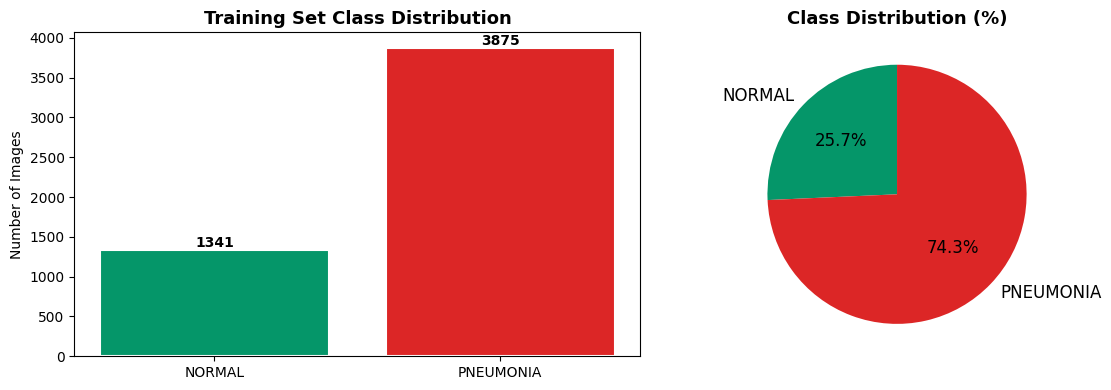

In [4]:
# Compute class weights to handle imbalance
# (Kaggle dataset has ~3x more pneumonia samples than normal)

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)
class_weights = dict(enumerate(class_weights_array))

print("Class distribution in training set:")
unique, counts = np.unique(train_data.classes, return_counts=True)
for cls, cnt in zip(unique, counts):
    print(f"  Class {cls} ({CLASS_NAMES[cls]}): {cnt} samples")

print(f"\nComputed class weights: {class_weights}")
print("  (Higher weight = model penalised more for missing that class)")

# ── Visualise class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
axes[0].bar(CLASS_NAMES, counts, color=['#059669', '#dc2626'], edgecolor='white', linewidth=1.5)
axes[0].set_title('Training Set Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Images')
for i, cnt in enumerate(counts):
    axes[0].text(i, cnt + 30, str(cnt), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(counts, labels=CLASS_NAMES, colors=['#059669', '#dc2626'],
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Class Distribution (%)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Visualise Sample Training Images

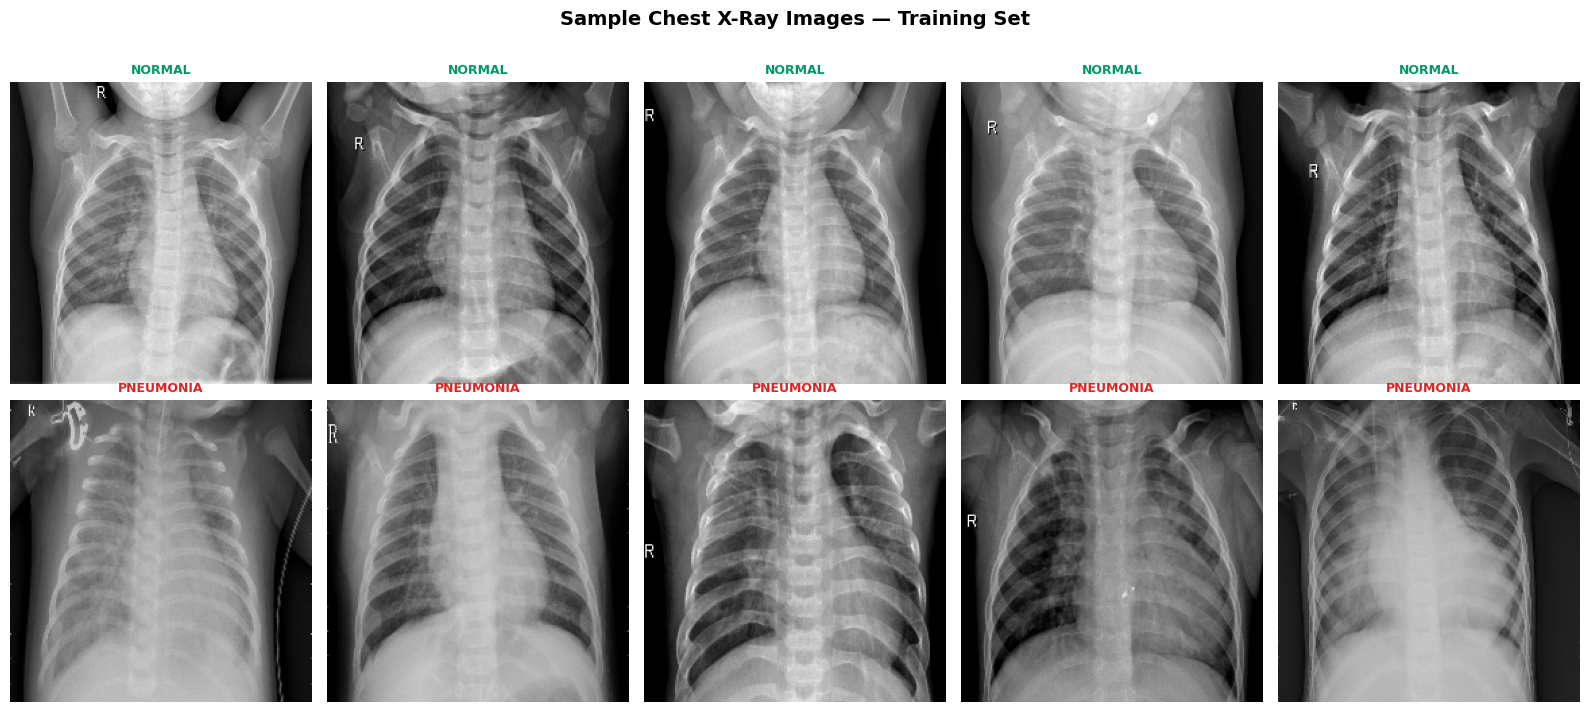

In [5]:
# Display sample X-rays from each class
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
fig.suptitle('Sample Chest X-Ray Images — Training Set', fontsize=14, fontweight='bold', y=1.02)

for class_idx, class_name in enumerate(CLASS_NAMES):
    class_dir = os.path.join(TRAIN_DIR, class_name)
    images = os.listdir(class_dir)[:5]
    for col, img_name in enumerate(images):
        img_path = os.path.join(class_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224))
        axes[class_idx][col].imshow(img, cmap='gray')
        axes[class_idx][col].set_title(class_name, fontsize=9,
            color='#059669' if class_name == 'NORMAL' else '#dc2626',
            fontweight='bold')
        axes[class_idx][col].axis('off')

plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Build Model — MobileNetV2 Transfer Learning

In [6]:
# ── Phase 1: Frozen base model ───────────────────────────────────────
# Load MobileNetV2 pre-trained on ImageNet
# include_top=False → remove ImageNet classification head

base_model = MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Freeze all base layers

# ── Custom classification head ─────────────────────────────────────────
inputs = tf.keras.Input(shape=IMG_SHAPE)
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)       # Reduce spatial dims
x = BatchNormalization()(x)            # Stabilise training
x = Dense(128, activation='relu')(x)  # Learnable features
x = Dropout(DROPOUT)(x)               # Regularisation
outputs = Dense(1, activation='sigmoid')(x)  # Binary output

model = Model(inputs, outputs)

# ── Compile with clinical metrics ─────────────────────────────────────
model.compile(
    optimizer=Adam(learning_rate=LR_P1),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

# ── Model summary ──────────────────────────────────────────────────────
total_params    = model.count_params()
trainable_params = sum([tf.size(w).numpy() for w in model.trainable_weights])
frozen_params   = total_params - trainable_params

print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}  (custom head only)")
print(f"Frozen parameters   : {frozen_params:,}  (MobileNetV2 base)")
model.summary()



Total parameters    : 2,427,201
Trainable parameters: 166,657  (custom head only)
Frozen parameters   : 2,260,544  (MobileNetV2 base)
Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 batch_normalization (Batch  (None, 1280)              5120      
 Normalization)                                                  
                                                         

## 7. Define Training Callbacks

In [7]:
# ── Callbacks ─────────────────────────────────────────────────────────

early_stop = EarlyStopping(
    monitor='val_auc',
    patience=5,             # Stop if no improvement for 5 epochs
    restore_best_weights=True,
    mode='max',
    verbose=1
)

checkpoint = ModelCheckpoint(
    MODEL_SAVE,
    monitor='val_auc',
    save_best_only=True,    # Only save if val_auc improves
    mode='max',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,             # Halve the learning rate
    patience=3,
    min_lr=1e-7,
    verbose=1
)

callbacks_p1 = [early_stop, checkpoint, reduce_lr]

print("Callbacks configured:")
print("  ✅ EarlyStopping    — monitors val_auc, patience=5")
print("  ✅ ModelCheckpoint  — saves best model to", MODEL_SAVE)
print("  ✅ ReduceLROnPlateau — halves LR if val_loss plateaus")

Callbacks configured:
  ✅ EarlyStopping    — monitors val_auc, patience=5
  ✅ ModelCheckpoint  — saves best model to pneumonia_mobilenetv2.h5
  ✅ ReduceLROnPlateau — halves LR if val_loss plateaus


## 8. Phase 1 Training — Frozen Base (Feature Extraction)

In [8]:
print("=" * 60)
print("PHASE 1: Training custom head with frozen MobileNetV2 base")
print("=" * 60)

history_p1 = model.fit(
    train_data,
    epochs=EPOCHS_P1,
    validation_data=val_data,
    class_weight=class_weights,
    callbacks=callbacks_p1,
    verbose=1
)

print("\nPhase 1 training complete.")
print(f"Best val_auc: {max(history_p1.history['val_auc']):.4f}")

PHASE 1: Training custom head with frozen MobileNetV2 base
Epoch 1/15


163/163 [==============================] - ETA: 0s - loss: 0.2179 - accuracy: 0.9041 - precision: 0.9752 - recall: 0.8937 - auc: 0.9726
Epoch 1: val_auc improved from -inf to 0.99219, saving model to pneumonia_mobilenetv2.h5
163/163 [==============================] - 135s 800ms/step - loss: 0.2179 - accuracy: 0.9041 - precision: 0.9752 - recall: 0.8937 - auc: 0.9726 - val_loss: 0.3598 - val_accuracy: 0.8125 - val_precision: 0.7273 - val_recall: 1.0000 - val_auc: 0.9922 - lr: 0.0010
Epoch 2/15
163/163 [==============================] - ETA: 0s - loss: 0.1488 - accuracy: 0.9448 - precision: 0.9823 - recall: 0.9427 - auc: 0.9863
Epoch 2: val_auc did not improve from 0.99219
163/163 [==============================] - 114s 697ms/step - loss: 0.1488 - accuracy: 0.9448 - precision: 0.9823 - recall: 0.9427 - auc: 0.9863 - val_loss: 0.2139 - val_accuracy: 0.9375 - val_precision: 0.8889 - val_recall: 1.0000 - val_auc: 0.9844

## 9. Phase 1 Training Curves

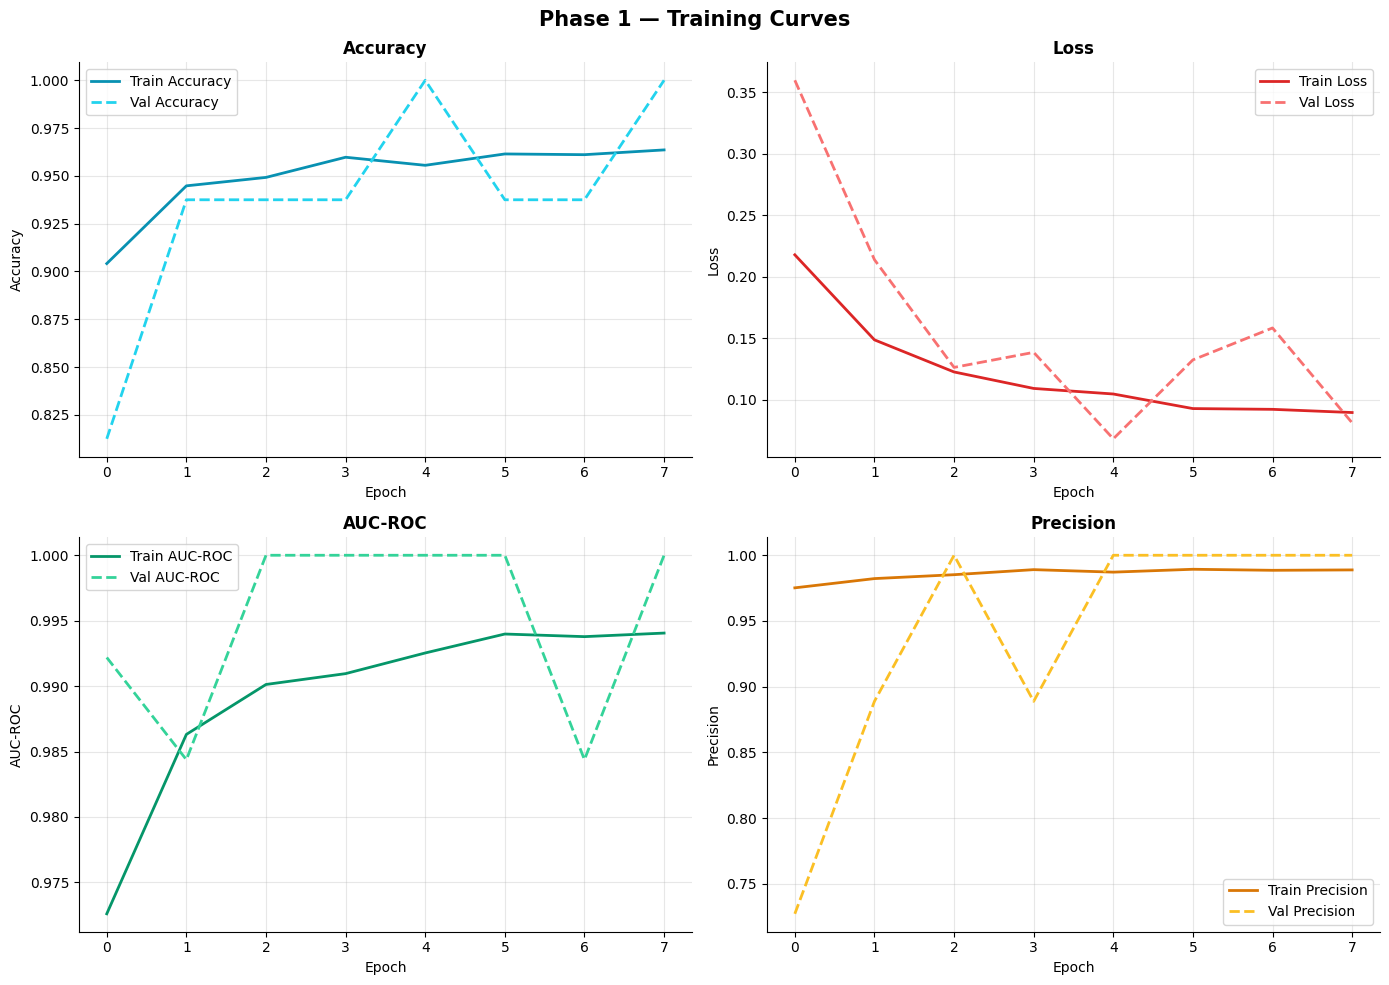

In [9]:
def plot_history(history, title_prefix='Phase 1'):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'{title_prefix} — Training Curves', fontsize=15, fontweight='bold')

    metrics = [
        ('accuracy',  'val_accuracy',  'Accuracy',  '#0891b2', '#22d3ee'),
        ('loss',      'val_loss',      'Loss',      '#dc2626', '#f87171'),
        ('auc',       'val_auc',       'AUC-ROC',   '#059669', '#34d399'),
        ('precision', 'val_precision', 'Precision', '#d97706', '#fbbf24'),
    ]

    for ax, (train_key, val_key, label, tc, vc) in zip(axes.flat, metrics):
        if train_key in history.history:
            ax.plot(history.history[train_key], color=tc, linewidth=2, label=f'Train {label}')
        if val_key in history.history:
            ax.plot(history.history[val_key], color=vc, linewidth=2,
                    linestyle='--', label=f'Val {label}')
        ax.set_title(label, fontweight='bold')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(label)
        ax.legend()
        ax.grid(True, alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(f'{title_prefix.lower().replace(" ","_")}_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

plot_history(history_p1, 'Phase 1')

## 10. Phase 2 — Fine-Tuning (Unfreeze Top Layers)

In [10]:
print("=" * 60)
print("PHASE 2: Fine-tuning — unfreeze last 30 MobileNetV2 layers")
print("=" * 60)

# Unfreeze the top layers of the base model
base_model.trainable = True
for layer in base_model.layers[:UNFREEZE_FROM]:
    layer.trainable = False

trainable_now = sum([tf.size(w).numpy() for w in model.trainable_weights])
print(f"Trainable parameters after unfreezing: {trainable_now:,}")

# Recompile with a much lower learning rate to avoid destroying pretrained weights
model.compile(
    optimizer=Adam(learning_rate=LR_P2),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

callbacks_p2 = [
    EarlyStopping(monitor='val_auc', patience=4, restore_best_weights=True,
                  mode='max', verbose=1),
    ModelCheckpoint(MODEL_SAVE, monitor='val_auc', save_best_only=True,
                    mode='max', verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2,
                      min_lr=1e-8, verbose=1)
]

history_p2 = model.fit(
    train_data,
    epochs=EPOCHS_P2,
    validation_data=val_data,
    class_weight=class_weights,
    callbacks=callbacks_p2,
    verbose=1
)

print("\nPhase 2 fine-tuning complete.")
print(f"Best val_auc: {max(history_p2.history['val_auc']):.4f}")

PHASE 2: Fine-tuning — unfreeze last 30 MobileNetV2 layers
Trainable parameters after unfreezing: 1,693,057
Epoch 1/10
163/163 [==============================] - ETA: 0s - loss: 0.1036 - accuracy: 0.9551 - precision: 0.9877 - recall: 0.9515 - auc: 0.9930
Epoch 1: val_auc improved from -inf to 1.00000, saving model to pneumonia_mobilenetv2.h5
163/163 [==============================] - 134s 790ms/step - loss: 0.1036 - accuracy: 0.9551 - precision: 0.9877 - recall: 0.9515 - auc: 0.9930 - val_loss: 0.0512 - val_accuracy: 1.0000 - val_precision: 1.0000 - val_recall: 1.0000 - val_auc: 1.0000 - lr: 1.0000e-05
Epoch 2/10
163/163 [==============================] - ETA: 0s - loss: 0.0938 - accuracy: 0.9597 - precision: 0.9919 - recall: 0.9535 - auc: 0.9939
Epoch 2: val_auc did not improve from 1.00000
163/163 [==============================] - 123s 756ms/step - loss: 0.0938 - accuracy: 0.9597 - precision: 0.9919 - recall: 0.9535 - auc: 0.9939 - val_loss: 0.0623 - val_accuracy: 1.0000 - val_preci

## 11. Phase 2 Training Curves

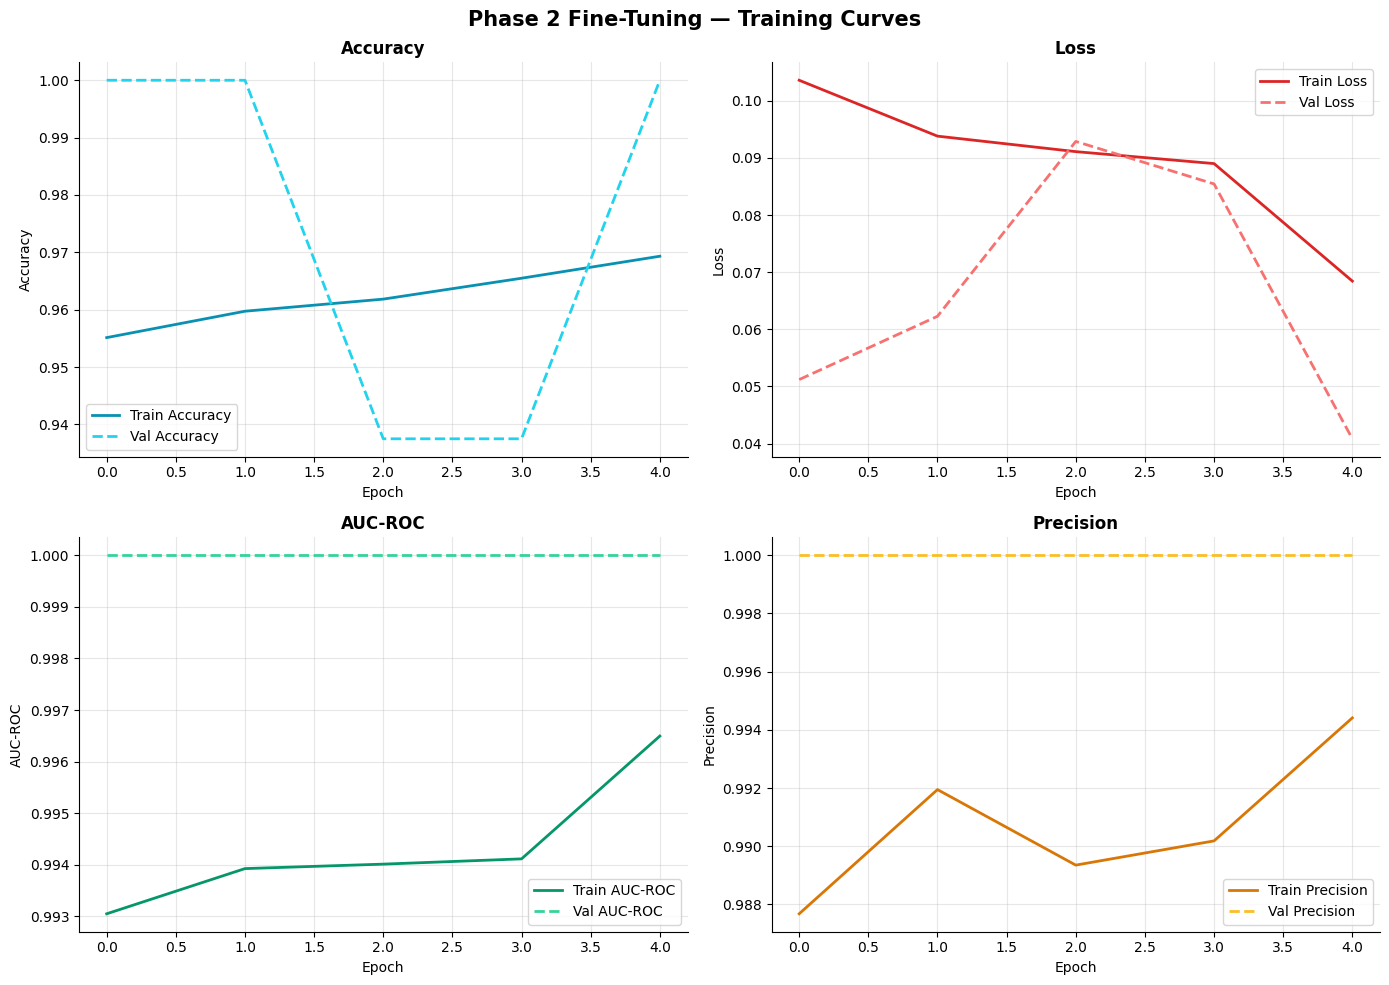

In [11]:
plot_history(history_p2, 'Phase 2 Fine-Tuning')

## 12. Final Evaluation on Test Set

In [12]:
print("=" * 60)
print("FINAL EVALUATION ON HELD-OUT TEST SET")
print("=" * 60)

test_data.reset()
results = model.evaluate(test_data, verbose=1)

metric_names = ['Loss', 'Accuracy', 'Precision', 'Recall', 'AUC']
print("\n── Test Set Results ──────────────────────────────────")
for name, val in zip(metric_names, results):
    print(f"  {name:12s}: {val:.4f}")

# Get predictions
test_data.reset()
y_pred_proba = model.predict(test_data, verbose=1)
y_pred = (y_pred_proba > 0.5).astype(int).flatten()
y_true = test_data.classes

print("\n── Classification Report ─────────────────────────────")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

FINAL EVALUATION ON HELD-OUT TEST SET
20/20 [==============================] - 10s 457ms/step - loss: 0.2888 - accuracy: 0.9071 - precision: 0.9368 - recall: 0.9128 - auc: 0.9634

── Test Set Results ──────────────────────────────────
  Loss        : 0.2888
  Accuracy    : 0.9071
  Precision   : 0.9368
  Recall      : 0.9128
  AUC         : 0.9634
20/20 [==============================] - 9s 409ms/step

── Classification Report ─────────────────────────────
              precision    recall  f1-score   support

      NORMAL     0.8607    0.8974    0.8787       234
   PNEUMONIA     0.9368    0.9128    0.9247       390

    accuracy                         0.9071       624
   macro avg     0.8987    0.9051    0.9017       624
weighted avg     0.9083    0.9071    0.9074       624



## 13. Confusion Matrix

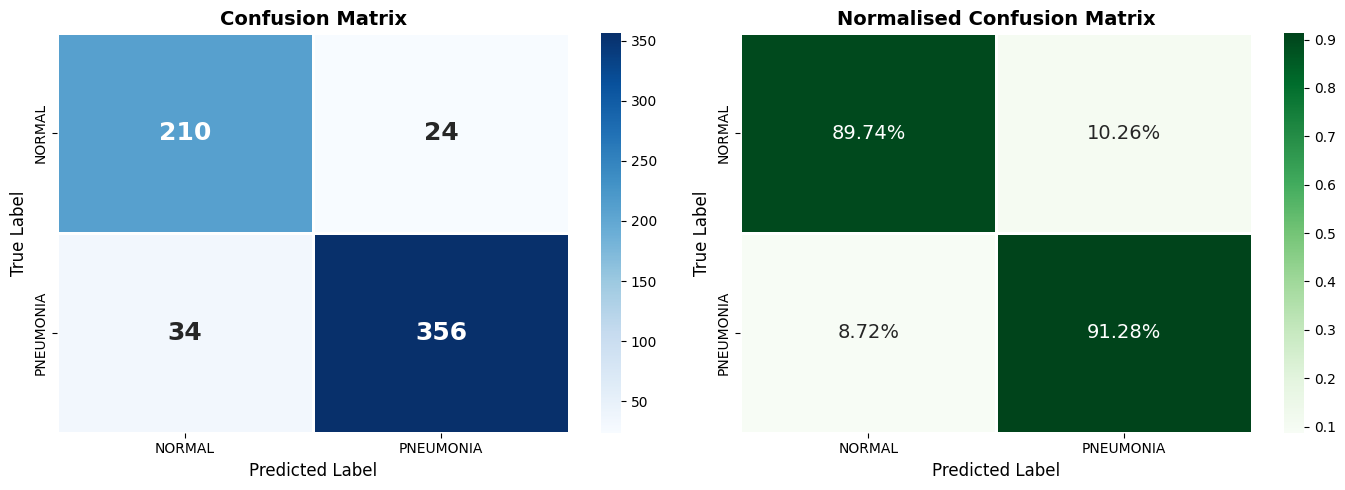


── Derived Metrics ───────────────────────────────────
  Sensitivity (Recall) : 0.9128  — ability to detect pneumonia
  Specificity          : 0.8974  — ability to identify normal
  PPV (Precision)      : 0.9368  — accuracy of positive prediction
  NPV                  : 0.8607  — accuracy of negative prediction
  F1 Score             : 0.9247  — harmonic mean of precision & recall


In [13]:
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0], linewidths=1, linecolor='white',
            annot_kws={"size": 18, "weight": "bold"})
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# Normalised confusion matrix
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], linewidths=1, linecolor='white',
            annot_kws={"size": 14})
axes[1].set_title('Normalised Confusion Matrix', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].set_xlabel('Predicted Label', fontsize=12)

plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n── Derived Metrics ───────────────────────────────────")
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
ppv         = tp / (tp + fp)
npv         = tn / (tn + fn)
f1          = 2 * tp / (2 * tp + fp + fn)
print(f"  Sensitivity (Recall) : {sensitivity:.4f}  — ability to detect pneumonia")
print(f"  Specificity          : {specificity:.4f}  — ability to identify normal")
print(f"  PPV (Precision)      : {ppv:.4f}  — accuracy of positive prediction")
print(f"  NPV                  : {npv:.4f}  — accuracy of negative prediction")
print(f"  F1 Score             : {f1:.4f}  — harmonic mean of precision & recall")

## 14. ROC Curve & AUC

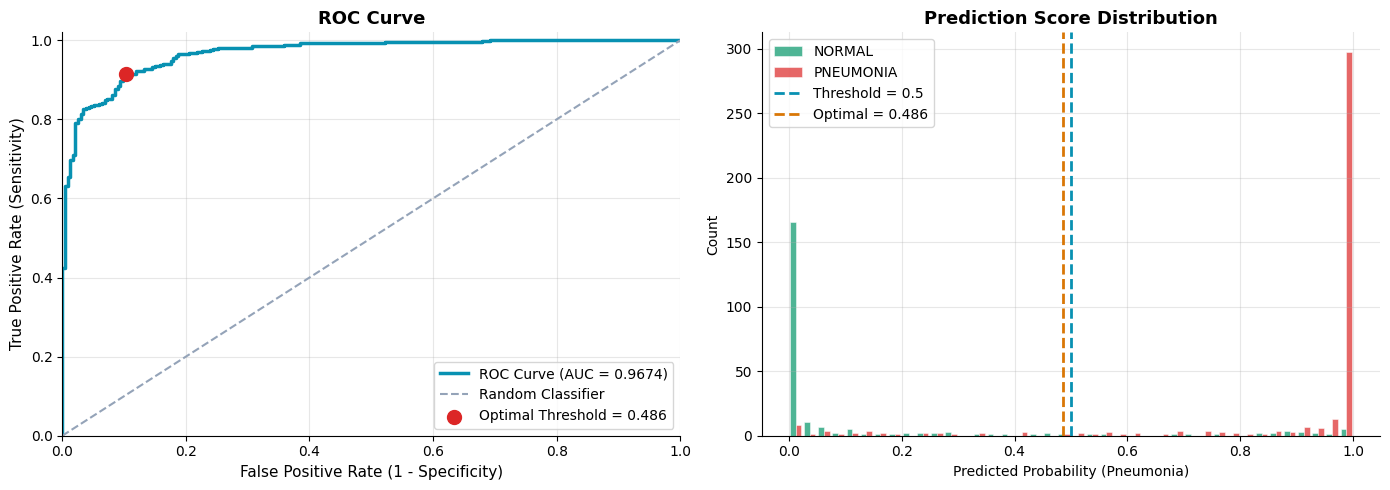


AUC-ROC Score       : 0.9674
Optimal Threshold   : 0.4863 (Youden's J statistic)
At optimal threshold: TPR=0.9154, FPR=0.1026


In [15]:
fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Find optimal threshold (Youden's J)
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
best_threshold = thresholds[best_idx]
best_fpr = fpr[best_idx]
best_tpr = tpr[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
axes[0].plot(fpr, tpr, color='#0891b2', lw=2.5,
             label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0,1], [0,1], color='#94a3b8', lw=1.5, linestyle='--', label='Random Classifier')
axes[0].scatter(best_fpr, best_tpr, color='#dc2626', s=100, zorder=5,
                label=f'Optimal Threshold = {best_threshold:.3f}')
axes[0].set_xlim([0, 1]); axes[0].set_ylim([0, 1.02])
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
axes[0].set_title('ROC Curve', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

# Prediction score distribution
axes[1].hist([y_pred_proba.flatten()[y_true==0], y_pred_proba.flatten()[y_true==1]],
             bins=40, color=['#059669','#dc2626'], alpha=0.7,
             label=CLASS_NAMES, edgecolor='white', linewidth=0.5)
axes[1].axvline(x=0.5, color='#0891b2', linestyle='--', lw=2, label='Threshold = 0.5')
axes[1].axvline(x=best_threshold, color='#d97706', linestyle='--', lw=2,
                label=f'Optimal = {best_threshold:.3f}')
axes[1].set_title('Prediction Score Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Probability (Pneumonia)')
axes[1].set_ylabel('Count')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nAUC-ROC Score       : {roc_auc:.4f}")
print(f"Optimal Threshold   : {best_threshold:.4f} (Youden's J statistic)")
print(f"At optimal threshold: TPR={best_tpr:.4f}, FPR={best_fpr:.4f}")

## 15. Grad-CAM — Explainability Visualisation

Grad-CAM highlights *which regions of the X-ray* the model focused on when making its prediction. This is crucial for medical AI credibility.

  Using inner conv layer: out_relu
  Using inner conv layer: out_relu
  Using inner conv layer: out_relu
  Using inner conv layer: out_relu


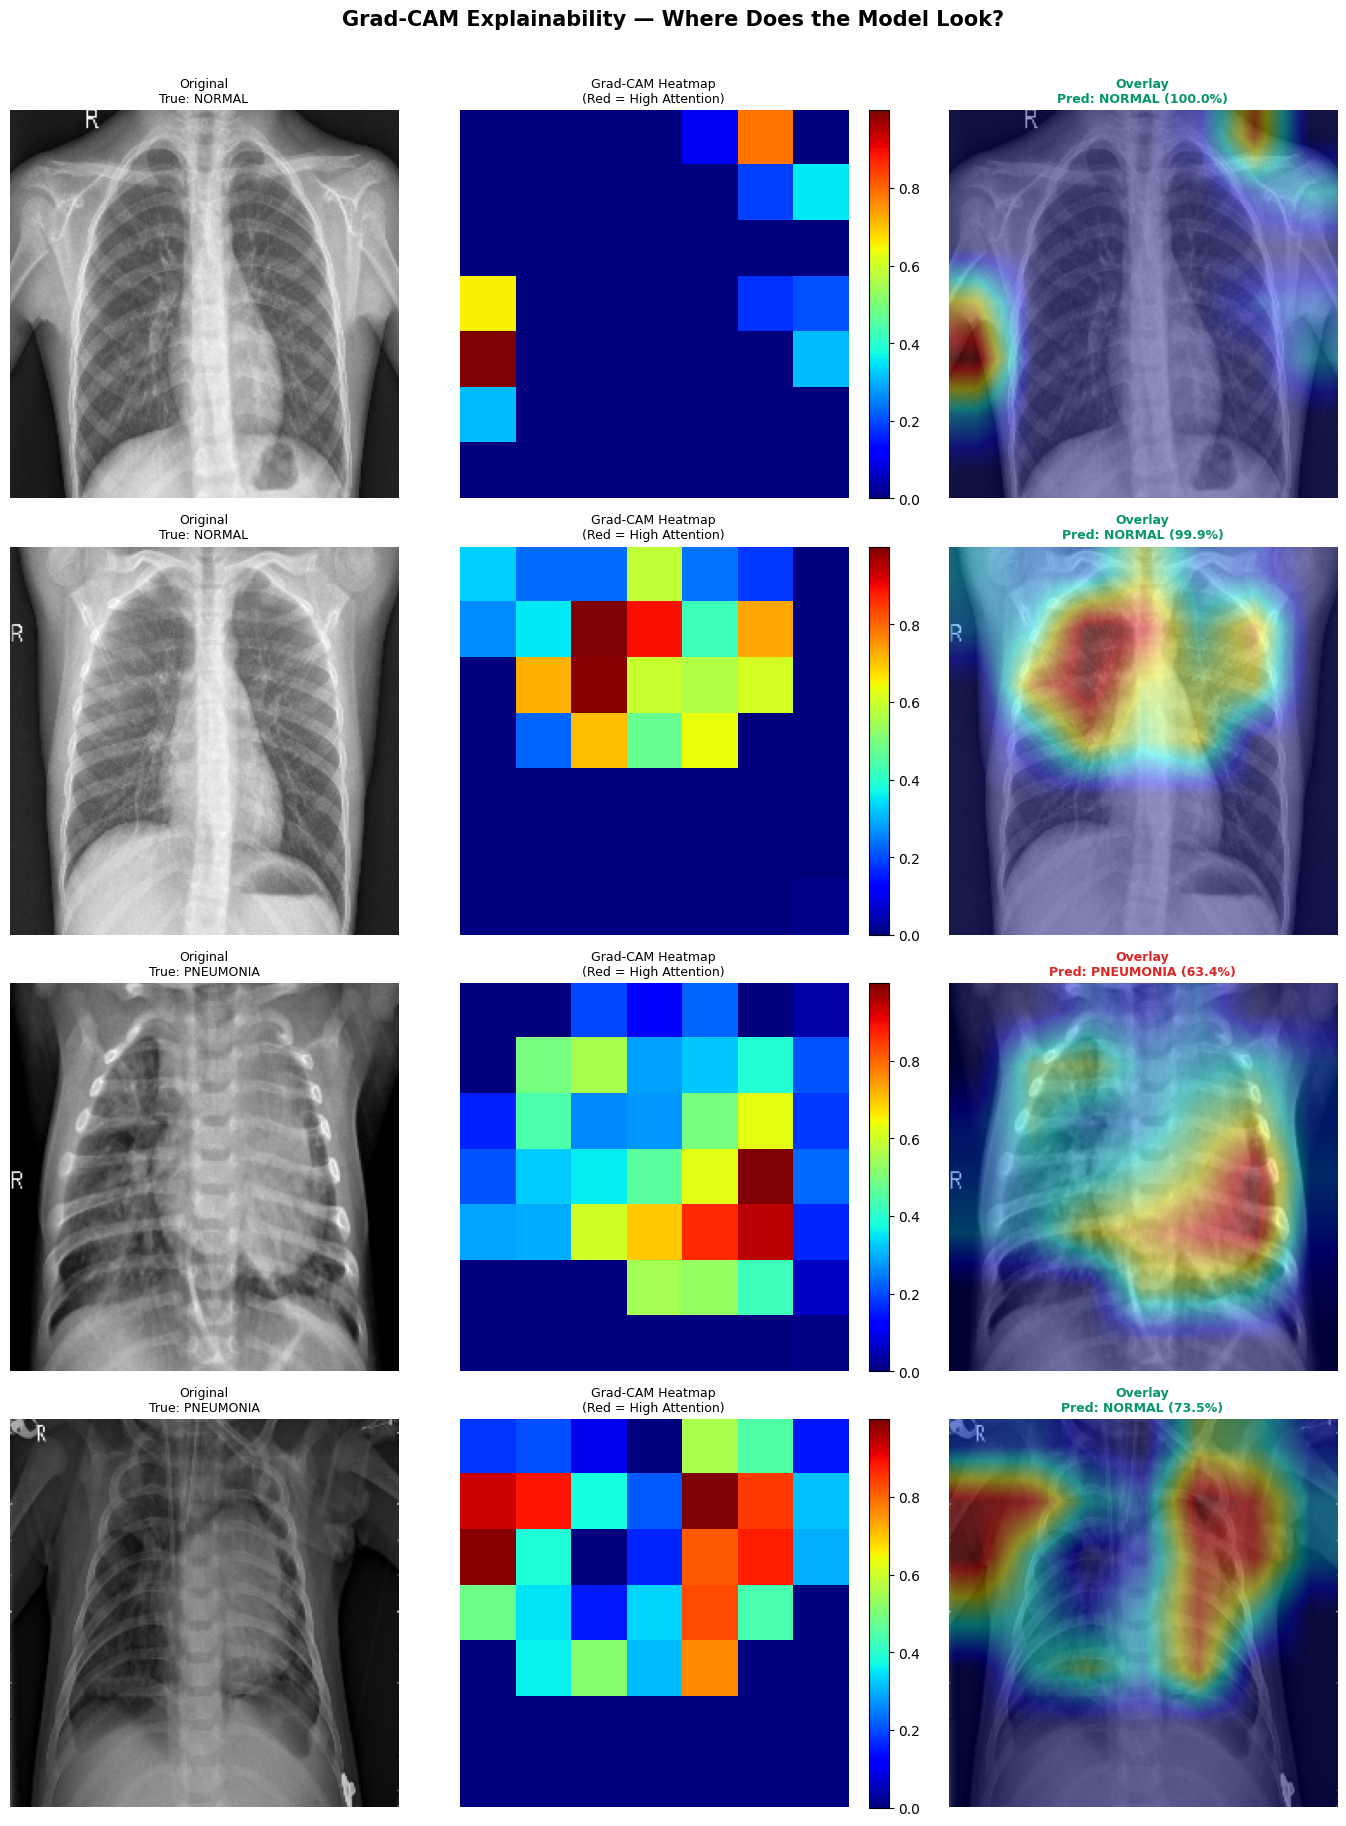

In [17]:
def get_gradcam_heatmap(model, img_array):
    """Grad-CAM that works with nested MobileNetV2 submodel."""
    # Get the MobileNetV2 base model from inside your Sequential/Functional model
    base_model = None
    for layer in model.layers:
        if 'mobilenetv2' in layer.name.lower():
            base_model = layer
            break

    if base_model is None:
        raise ValueError("Could not find MobileNetV2 base model")

    # Find last conv layer INSIDE the base model
    last_conv_layer = None
    for layer in reversed(base_model.layers):
        if hasattr(layer, 'output_shape'):
            try:
                if len(layer.output_shape) == 4:
                    last_conv_layer = layer.name
                    break
            except:
                pass

    print(f"  Using inner conv layer: {last_conv_layer}")

    # Build grad model using base_model's input and output
    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[base_model.get_layer(last_conv_layer).output, base_model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_out = grad_model(img_array)
        # Pass base output through remaining layers of main model
        x = base_out
        reached_base = False
        for layer in model.layers:
            if 'mobilenetv2' in layer.name.lower():
                reached_base = True
                continue
            if reached_base:
                x = layer(x)
        loss = x[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_gradcam(img_path, heatmap, alpha=0.4):
    """Overlay Grad-CAM heatmap on original image."""
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_colored = np.uint8(255 * heatmap_resized)
    heatmap_colored = cv2.applyColorMap(heatmap_colored, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    superimposed = cv2.addWeighted(img, 1 - alpha, heatmap_colored, alpha, 0)
    return img, superimposed


# Pick sample images: 2 normal, 2 pneumonia
samples = {
    'NORMAL'   : os.listdir(os.path.join(TEST_DIR, 'NORMAL'))[:2],
    'PNEUMONIA': os.listdir(os.path.join(TEST_DIR, 'PNEUMONIA'))[:2]
}

fig, axes = plt.subplots(4, 3, figsize=(14, 18))
fig.suptitle('Grad-CAM Explainability — Where Does the Model Look?',
             fontsize=15, fontweight='bold', y=1.01)

row = 0
for class_name, img_names in samples.items():
    for img_name in img_names:
        img_path = os.path.join(TEST_DIR, class_name, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img, (224, 224))
        img_array = np.expand_dims(img_resized / 255.0, axis=0).astype('float32')

        pred_prob = model.predict(img_array, verbose=0)[0][0]
        pred_label = 'PNEUMONIA' if pred_prob > 0.5 else 'NORMAL'
        confidence = pred_prob if pred_prob > 0.5 else 1 - pred_prob

        try:
            heatmap = get_gradcam_heatmap(model, img_array)
            original, overlay = overlay_gradcam(img_path, heatmap)
            color = '#dc2626' if pred_label == 'PNEUMONIA' else '#059669'

            axes[row][0].imshow(original)
            axes[row][0].set_title(f'Original\nTrue: {class_name}', fontsize=9)
            axes[row][0].axis('off')

            hm_vis = axes[row][1].imshow(heatmap, cmap='jet')
            axes[row][1].set_title('Grad-CAM Heatmap\n(Red = High Attention)', fontsize=9)
            axes[row][1].axis('off')
            plt.colorbar(hm_vis, ax=axes[row][1], fraction=0.046)

            axes[row][2].imshow(overlay)
            axes[row][2].set_title(
                f'Overlay\nPred: {pred_label} ({confidence:.1%})',
                fontsize=9, color=color, fontweight='bold')
            axes[row][2].axis('off')

        except Exception as e:
            print(f"Grad-CAM failed for {img_name}: {e}")

        row += 1

plt.tight_layout()
plt.savefig('gradcam_visualisation.png', dpi=150, bbox_inches='tight')
plt.show()

## 16. Save Final Model

In [18]:
# Save in both .h5 and SavedModel format
model.save(MODEL_SAVE)
print(f"✅ Model saved to: {MODEL_SAVE}")

# Also save in SavedModel format (better for deployment)
saved_model_path = "pneumonia_saved_model"
model.save(saved_model_path)
print(f"✅ SavedModel saved to: {saved_model_path}/")

# Model size
h5_size = os.path.getsize(MODEL_SAVE) / (1024 * 1024)
print(f"   .h5 file size: {h5_size:.1f} MB")


✅ Model saved to: pneumonia_mobilenetv2.h5
INFO:tensorflow:Assets written to: pneumonia_saved_model\assets


INFO:tensorflow:Assets written to: pneumonia_saved_model\assets


✅ SavedModel saved to: pneumonia_saved_model/
   .h5 file size: 22.6 MB


## 17. Final Summary Dashboard

In [19]:
print("\n" + "="*65)
print("          PNEUMOAI — FINAL MODEL SUMMARY")
print("="*65)
print(f"  Architecture      : MobileNetV2 (ImageNet pre-trained)")
print(f"  Input shape       : {IMG_SHAPE}")
print(f"  Total parameters  : {model.count_params():,}")
print(f"  Batch size        : {BATCH_SIZE}")
print(f"  Phase 1 epochs    : {len(history_p1.history['loss'])}")
print(f"  Phase 2 epochs    : {len(history_p2.history['loss'])}")
print()
test_results = dict(zip(metric_names, results))
print(f"  Test Accuracy     : {test_results['Accuracy']:.4f} ({test_results['Accuracy']*100:.2f}%)")
print(f"  Test AUC-ROC      : {test_results['AUC']:.4f}")
print(f"  Test Precision    : {test_results['Precision']:.4f}")
print(f"  Test Recall       : {test_results['Recall']:.4f}")
print(f"  Sensitivity       : {sensitivity:.4f}")
print(f"  Specificity       : {specificity:.4f}")
print(f"  F1 Score          : {f1:.4f}")
print()
print(f"  Saved model       : {MODEL_SAVE}")
print("="*65)
print()
print("Generated files:")
for fname in ['class_distribution.png','sample_images.png',
              'phase_1_curves.png','phase_2_fine-tuning_curves.png',
              'confusion_matrix.png','roc_curve.png',
              'gradcam_visualisation.png', MODEL_SAVE]:
    exists = "✅" if os.path.exists(fname) else "❌"
    print(f"  {exists} {fname}")



          PNEUMOAI — FINAL MODEL SUMMARY
  Architecture      : MobileNetV2 (ImageNet pre-trained)
  Input shape       : (224, 224, 3)
  Total parameters  : 2,427,201
  Batch size        : 32
  Phase 1 epochs    : 8
  Phase 2 epochs    : 5

  Test Accuracy     : 0.9071 (90.71%)
  Test AUC-ROC      : 0.9634
  Test Precision    : 0.9368
  Test Recall       : 0.9128
  Sensitivity       : 0.9128
  Specificity       : 0.8974
  F1 Score          : 0.9247

  Saved model       : pneumonia_mobilenetv2.h5

Generated files:
  ✅ class_distribution.png
  ✅ sample_images.png
  ✅ phase_1_curves.png
  ✅ phase_2_fine-tuning_curves.png
  ✅ confusion_matrix.png
  ✅ roc_curve.png
  ✅ gradcam_visualisation.png
  ✅ pneumonia_mobilenetv2.h5
